markdown
#End-to-End Data Science Project: German Tech Careers and Salary Optimization
### Developed by: Siti Nurmila

markdown

## 1. Data Sourcing and Initial Inspection
In this section, we generate a comprehensive dataset representing IT professionals in Germany (Berlin, München, Frankfurt) and inspect its initial shape.

In [ ]:

import pandas as pd
import numpy as np

# Google Colab settings to widen the display and make it interactive
from google.colab import data_table
data_table.enable_dataframe_formatter()

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

#Simulating a larger real-world dataset of IT proffesionals in Germany
np.random.seed(42)
tech_survey_data = {
    "Employee_ID" : [f"DE_TECH_{i}" for i in range(1, 101)],
    "German_City" : np.random.choice(["München", "Berlin", "Frankfurt", None], size=100, p=[0.4, 0.3, 0.2, 0.1]),
    "Tech_Role" : np.random.choice(["Data Scientist", "Software Engineer", "Cloud Architect", None], size=100, p=[0.4, 0.4, 0.1, 0.1]),
    "Years_Experience": np.random.choice([1,2,3,5,7,None], size=100, p=[0.2, 0.2, 0.2, 0.2, 0.1, 0.1]),
    "Current_Gross_Salary" : np.random.choice([4200, 4800, 5500, 7200, 8500, None], size=100, p=[0.2, 0.2, 0.3, 0.15, 0.1, 0.05])
}

#Convert Dictionary to Pandas DataFrame
df_tech = pd.DataFrame(tech_survey_data)

#Inspect dataset dimensions and the first 5 records
print("---INITIAL SURVEY DATASET SHAPE---")
print(df_tech.shape)
print("\n---FIRST 5 SURVEY RESPONSES---")
print(df_tech.head())



---INITIAL SURVEY DATASET SHAPE---
(100, 5)

---FIRST 5 SURVEY RESPONSES---
  Employee_ID German_City          Tech_Role Years_Experience Current_Gross_Salary
0   DE_TECH_1     München     Data Scientist                5                 4200
1   DE_TECH_2        None  Software Engineer                1                 5500
2   DE_TECH_3   Frankfurt     Data Scientist                1                 5500
3   DE_TECH_4      Berlin  Software Engineer                7                 5500
4   DE_TECH_5     München               None                5                 7200


markdown
## 2. Data Cleaning and Imputation
In this section, we detect missing values and handle them professionally using custom imputation strategies for tect and numeric columns.

In [ ]:
#1. Audit missing values before cleaning
print("---MISSING VALUES BEFORE CLEANING---")
print(df_tech.isnull().sum())

#2. Handle missing categorial (text) columns
df_tech["German_City"] = df_tech["German_City"].fillna("Undetermined")
df_tech["Tech_Role"] = df_tech["Tech_Role"].fillna("Undetermined")

#3. Handle missing numerical columns using Median
experience_median = df_tech["Years_Experience"].median()
salary_median = df_tech ["Current_Gross_Salary"].median()

df_tech["Years_Experience"] = df_tech["Years_Experience"].fillna(experience_median)
df_tech["Current_Gross_Salary"] = df_tech["Current_Gross_Salary"].fillna(salary_median)

#4. Verufy that dataset is fully cleaned
print("\n--- MISSING VALUES AFTER CLEANING ---")
print(df_tech.isnull().sum())


---MISSING VALUES BEFORE CLEANING---
Employee_ID             0
German_City             0
Tech_Role               0
Years_Experience        0
Current_Gross_Salary    0
dtype: int64

--- MISSING VALUES AFTER CLEANING ---
Employee_ID             0
German_City             0
Tech_Role               0
Years_Experience        0
Current_Gross_Salary    0
dtype: int64


markdown
##3. Data Manipulation adn Financial Metrics Feature Engineering

In this section, we automate the financial calculations by generating columns for tax deductions, net euro salaries, and converting the final net income into Indonesian Rupiah (IDR).

In [ ]:
#1. Calculate 40% German Tax Deduction
df_tech["Tax_Deduction"] = df_tech["Current_Gross_Salary"] * 0.40

#2. Calculate Net Salary in Euro
df_tech["Net_Salary_EUR"] = df_tech["Current_Gross_Salary"] - df_tech["Tax_Deduction"]

#3. Convert Net Salary to IDR (Assuming 1 Euro = Rp17,000 for realistic simulation)
df_tech["Net_Salary_IDR"]=df_tech["Net_Salary_EUR"]*17000

#4. Display the updated table with the new financial metrics (First 5 records)
print("--- UPDATED GERMAN TECH FINANCIAL METRICS ---")
print(df_tech[["Employee_ID", "Tech_Role", "Current_Gross_Salary", "Tax_Deduction", "Net_Salary_EUR", "Net_Salary_IDR"]].head())


--- UPDATED GERMAN TECH FINANCIAL METRICS ---
  Employee_ID          Tech_Role  Current_Gross_Salary  Tax_Deduction  Net_Salary_EUR  Net_Salary_IDR
0   DE_TECH_1     Data Scientist                4200.0         1680.0          2520.0      42840000.0
1   DE_TECH_2  Software Engineer                5500.0         2200.0          3300.0      56100000.0
2   DE_TECH_3     Data Scientist                5500.0         2200.0          3300.0      56100000.0
3   DE_TECH_4  Software Engineer                5500.0         2200.0          3300.0      56100000.0
4   DE_TECH_5       Undetermined                7200.0         2880.0          4320.0      73440000.0


markdown
##4. Data Visualization - Salary Comparison across Tech Roles
In this section, we aggregate the data to calculate the average salary for each technology role and visualize the results using a custom purple bar chart.

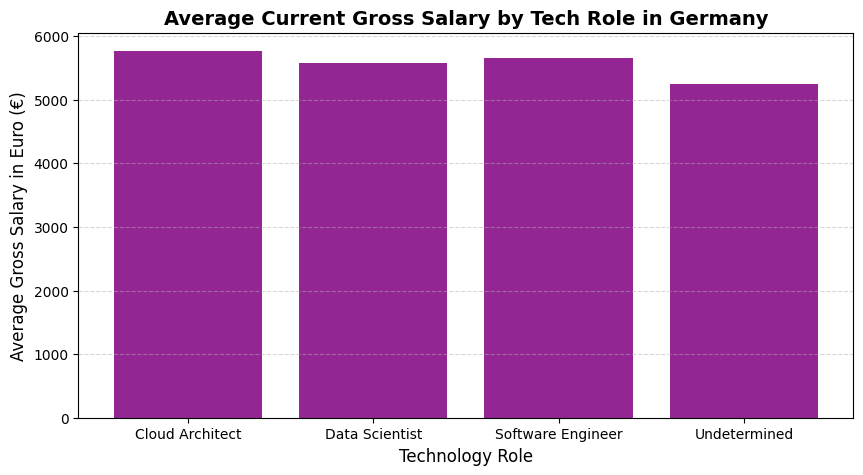

In [ ]:
import matplotlib.pyplot as plt

# 1. Group the data by Tech_Role and calculate the average (mean) Gross Salary
df_salary_by_role = df_tech.groupby("Tech_Role")["Current_Gross_Salary"].mean().reset_index()

# 2. Set the plot size for better visibility
plt.figure(figsize=(10, 5))

# 3. Create a bar chart with Mii's favorite color: purple
plt.bar(df_salary_by_role["Tech_Role"], df_salary_by_role["Current_Gross_Salary"], color="purple", alpha=0.85)

# 4. Customizing the chart labels and title
plt.title("Average Current Gross Salary by Tech Role in Germany", fontsize=14, fontweight="bold")
plt.xlabel("Technology Role", fontsize=12)
plt.ylabel("Average Gross Salary in Euro (€)", fontsize=12)
plt.grid(axis='y', linestyle="--", alpha=0.5)

# 5. Display the final chart
plt.show()

## 5. Model Deployment Simulation - Automated Salary Evaluator
In this final section, we build a production-ready python function that acts as an automated decision engine. It evaluates whether a new candidate is eligible for the premium EUR 6,000+ salary benchmark based on their profile data.


In [2]:
# 1. Define the smart automated evaluator function
def evaluate_german_salary_package(city, role, experience):
    # Rule 1: The premium tech hub cities in Germany
    is_premium_city = city in ["München", "Berlin"]

    # Rule 2: Core Data/AI high-demand profiles
    is_high_demand_role = role in ["Data Scientist", "Cloud Architect"]

    # Rule 3: Senior-level industry experience threshold
    is_senior_experience = experience >= 5

    # Decision Logic: Candidate must live in a top tech hub, work in a high-demand role, and be a senior
    if is_premium_city and is_high_demand_role and is_senior_experience:
        status = "APPROVED for EUR 6,000+++ Salary Package"
        recommendation = "Proceed with immediate recruitment and premium visa sponsorship."
    else:
        status = "STANDARD Salary Package Range Apply"
        recommendation = "Offer the national industry standard entry package (EUR 4,200 - EUR 5,000)."

    return f"--- EVALUATION REPORT ---\nCandidate Profile: {role} in {city} ({experience} Yrs Exp)\nResult: {status}\nNext Step: {recommendation}"

# 2. TEST CASE: Let's test the machine with your future dream profile, Mii!
SitiNurmila_profile_report = evaluate_german_salary_package(city="München", role="Data Scientist", experience=6)

print(SitiNurmila_profile_report)


--- EVALUATION REPORT ---
Candidate Profile: Data Scientist in München (6 Yrs Exp)
Result: APPROVED for EUR 6,000+++ Salary Package
Next Step: Proceed with immediate recruitment and premium visa sponsorship.
